In [2]:
# ==========================================
# CELL 1: Load & Inspect Benchmark Leaderboard
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the 5-fold cross-validation benchmark results
benchmark_df = pd.read_csv("../data/baseline_benchmark_results.csv")

print("--- Full 18-Experiment Benchmark Leaderboard (Sorted by F1-Score) ---")
leaderboard = benchmark_df.sort_values(
    by="F1_Score", ascending=False).reset_index(drop=True)
display(leaderboard.style.background_gradient(cmap="YlGnBu", subset=["Recall", "F1_Score", "ROC_AUC", "PR_AUC"]).format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1_Score": "{:.4f}", "ROC_AUC": "{:.4f}", "PR_AUC": "{:.4f}"
}))

--- Full 18-Experiment Benchmark Leaderboard (Sorted by F1-Score) ---


,Model,Strategy,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Random Forest,SMOTE,0.8096,0.5389,0.4595,0.4957,0.7915,0.5267
1,XGBoost,Class-Weighted,0.7882,0.4818,0.5067,0.4938,0.7676,0.5123
2,Random Forest,Class-Weighted,0.8148,0.5585,0.4398,0.4915,0.7905,0.5320
3,XGBoost,SMOTE,0.8169,0.5765,0.3851,0.4612,0.7695,0.5154
4,Logistic Regression,Class-Weighted,0.6848,0.3530,0.6552,0.4588,0.7344,0.4527
5,Logistic Regression,SMOTE,0.6826,0.3516,0.6595,0.4587,0.7341,0.4517
6,Gaussian Naive Bayes,Class-Weighted,0.6715,0.3368,0.6307,0.4391,0.7119,0.4256
7,Gaussian Naive Bayes,SMOTE,0.6504,0.3223,0.6476,0.4304,0.7063,0.4287
8,XGBoost,Unadjusted,0.8163,0.5871,0.3413,0.4300,0.7719,0.5151
9,Gaussian Naive Bayes,Unadjusted,0.7626,0.4188,0.4243,0.4214,0.7119,0.4256


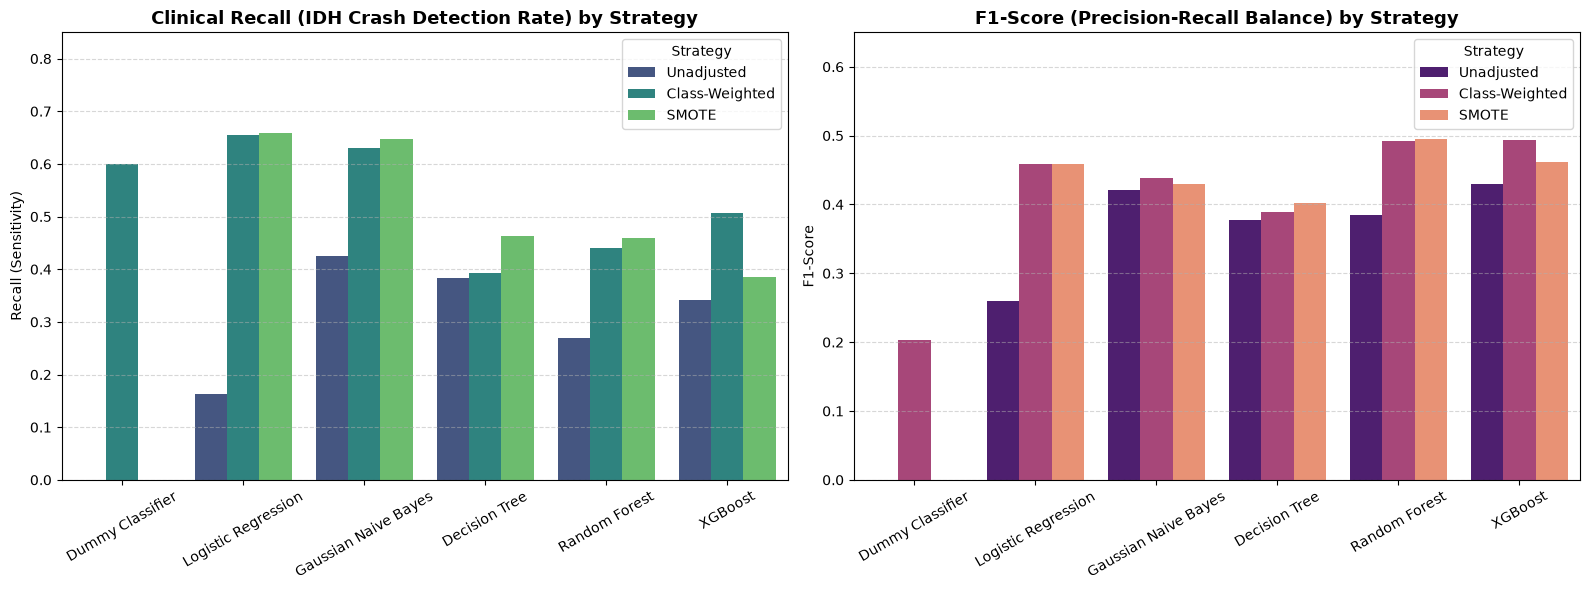

In [3]:
# ==========================================
# CELL 2: Strategy Impact on Recall & F1-Score
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Clinical Recall (Sensitivity) by Strategy
sns.barplot(
    data=benchmark_df, x="Model", y="Recall", hue="Strategy",
    palette="viridis", ax=axes[0]
)
axes[0].set_title("Clinical Recall (IDH Crash Detection Rate) by Strategy",
                  fontsize=13, fontweight="bold")
axes[0].set_ylabel("Recall (Sensitivity)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0, 0.85)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot 2: F1-Score Balance by Strategy
sns.barplot(
    data=benchmark_df, x="Model", y="F1_Score", hue="Strategy",
    palette="magma", ax=axes[1]
)
axes[1].set_title("F1-Score (Precision-Recall Balance) by Strategy",
                  fontsize=13, fontweight="bold")
axes[1].set_ylabel("F1-Score")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_ylim(0, 0.65)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

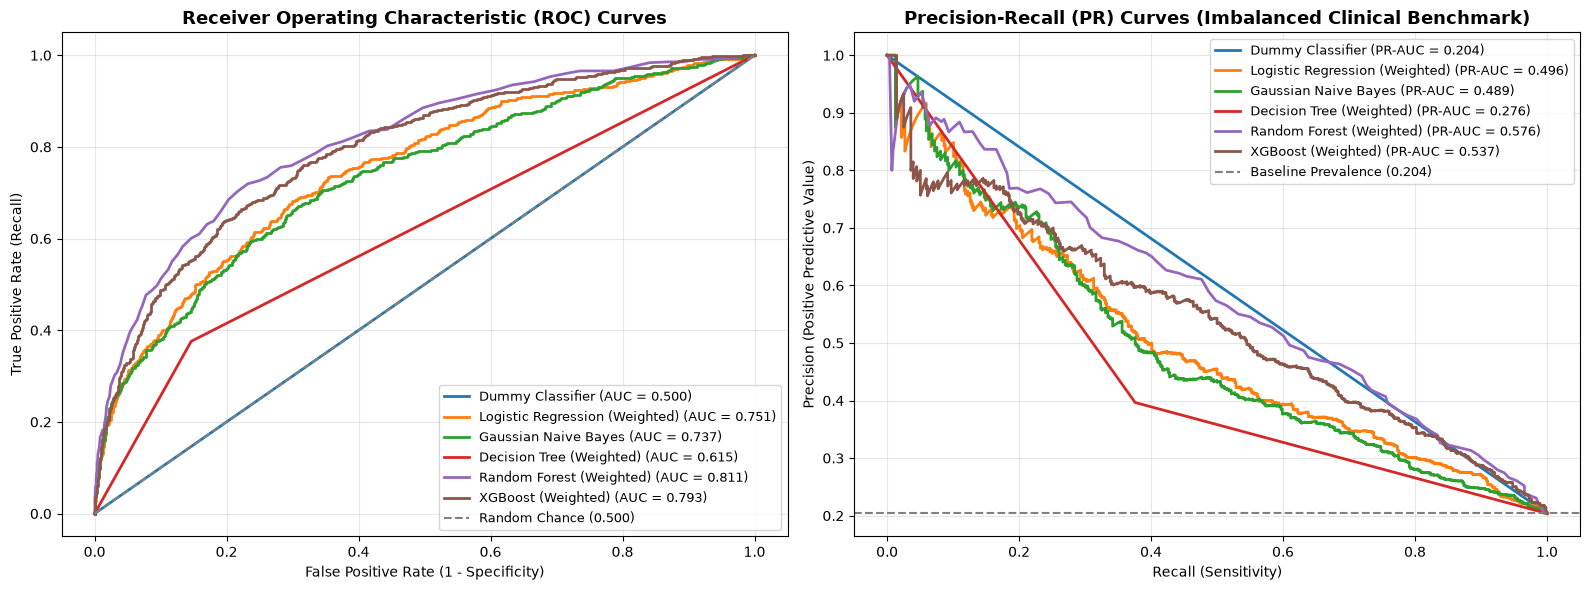

In [4]:
# ==========================================
# CELL 3: Overlay ROC and Precision-Recall Curves
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Load processed dataset and create stratified 80/20 evaluation split
df = pd.read_csv("../data/processed_dataset_10.csv")
X = df.drop(columns=["Hypotension"])
y = df["Hypotension"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Dummy Classifier": DummyClassifier(strategy="prior", random_state=42),
    "Logistic Regression (Weighted)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree (Weighted)": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Random Forest (Weighted)": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1),
    "XGBoost (Weighted)": XGBClassifier(n_estimators=100, scale_pos_weight=pos_weight, eval_metric="logloss", random_state=42, n_jobs=-1)
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    y_prob = model.predict_proba(X_test)[:, 1]

    # 1. ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.3f})")

    # 2. Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    axes[1].plot(recall, precision, lw=2,
                 label=f"{name} (PR-AUC = {pr_auc:.3f})")

# Format ROC Plot
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--",
             label="Random Chance (0.500)")
axes[0].set_title("Receiver Operating Characteristic (ROC) Curves",
                  fontsize=13, fontweight="bold")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right", fontsize=9)
axes[0].grid(alpha=0.3)

# Format PR Plot
baseline_prevalence = y_test.mean()
axes[1].axhline(y=baseline_prevalence, color="gray", linestyle="--",
                label=f"Baseline Prevalence ({baseline_prevalence:.3f})")
axes[1].set_title("Precision-Recall (PR) Curves (Imbalanced Clinical Benchmark)",
                  fontsize=13, fontweight="bold")
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision (Positive Predictive Value)")
axes[1].legend(loc="upper right", fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

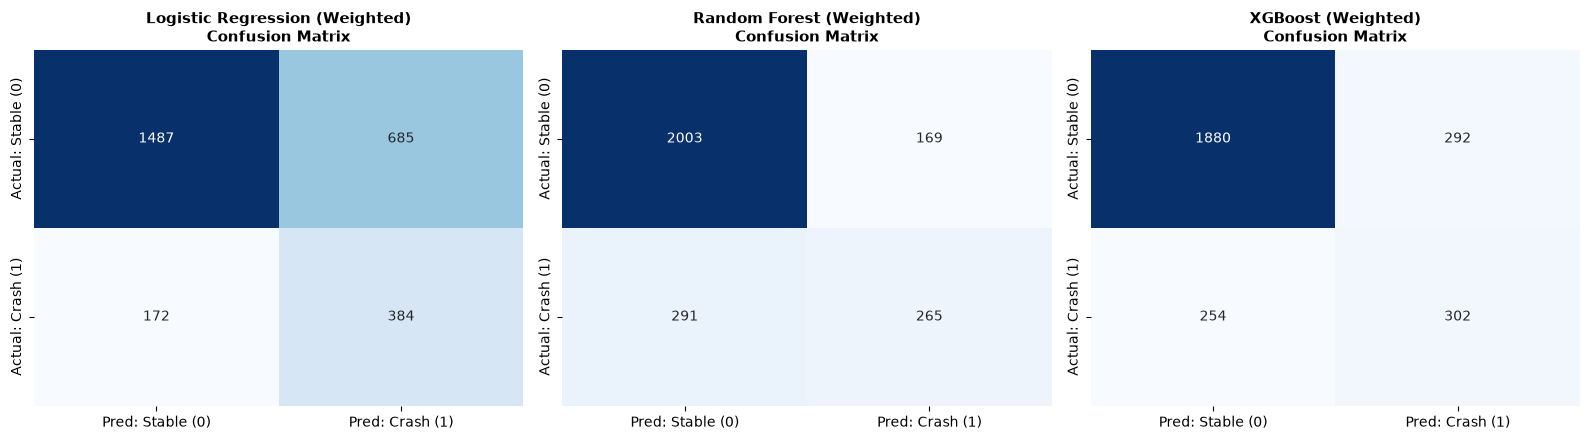

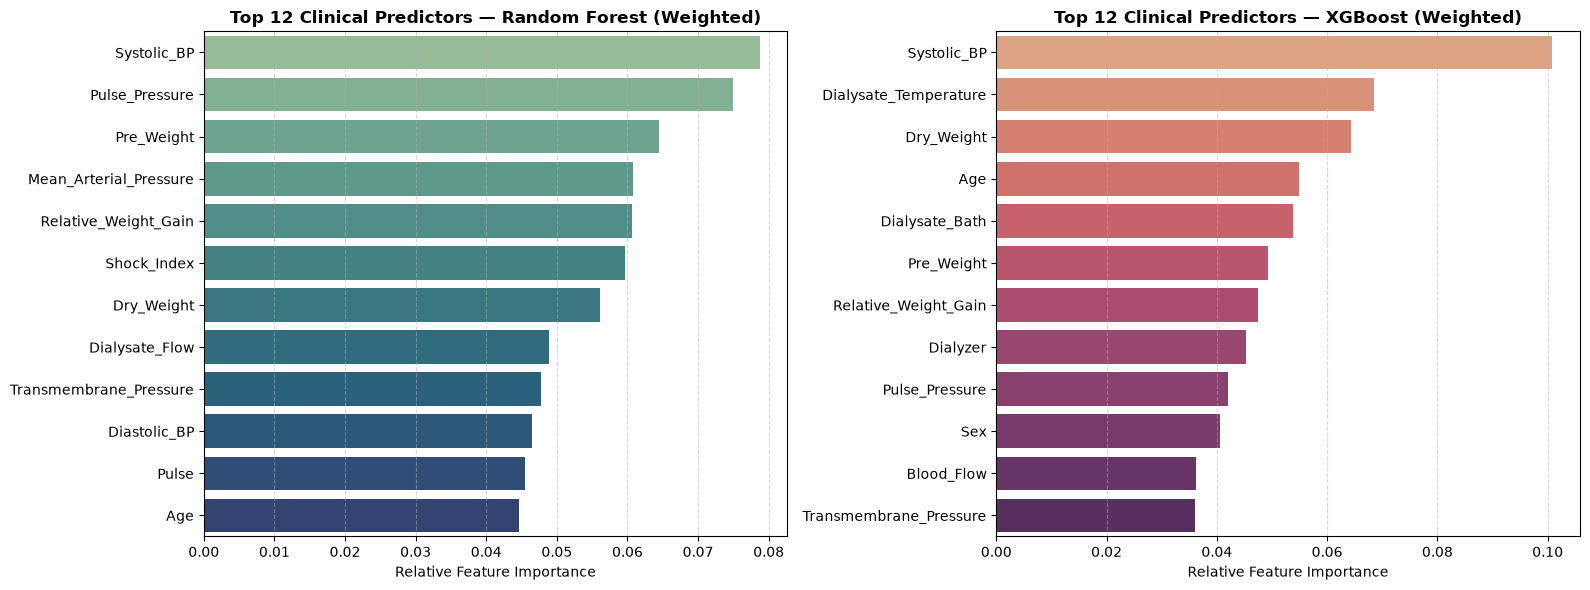

In [6]:
# ==========================================
# CELL 4: Confusion Matrices & Feature Importance
# ==========================================
from sklearn.metrics import confusion_matrix

# 1. Plot Side-by-Side Confusion Matrices for Top 3 Models
top_models = ["Logistic Regression (Weighted)",
              "Random Forest (Weighted)", "XGBoost (Weighted)"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, name in zip(axes, top_models):
    y_pred = trained_models[name].predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Pred: Stable (0)", "Pred: Crash (1)"],
        yticklabels=["Actual: Stable (0)", "Actual: Crash (1)"]
    )
    ax.set_title(f"{name}\nConfusion Matrix", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

# 2. Plot Top 12 Clinical & Engineered Feature Importances (Random Forest & XGBoost)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, name, palette in zip(axes, ["Random Forest (Weighted)", "XGBoost (Weighted)"], ["crest", "flare"]):
    importances = trained_models[name].feature_importances_
    feat_df = pd.DataFrame({
        "Feature": X.columns,
        "Importance": importances
    }).sort_values(by="Importance", ascending=False).head(12)

    sns.barplot(
        data=feat_df, x="Importance", y="Feature",
        hue="Feature", palette=palette, legend=False, ax=ax
    )
    ax.set_title(
        f"Top 12 Clinical Predictors — {name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Relative Feature Importance")
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()